# Modelo e avaliação — EEGNet no BCI IV 2a

Predições do EEGNet (Lawhern et al., 2018) treinado com divisão **por sujeito** (`GroupKFold`,
3 folds) em [`../src/train.py`](../src/train.py). Cada trial é predito pelo modelo do fold em que
o seu sujeito ficou no **teste**. Síntese no [`../README.md`](../README.md) (seção 13).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.metrics import (
    ConfusionMatrixDisplay, accuracy_score, balanced_accuracy_score, cohen_kappa_score,
    confusion_matrix, f1_score, matthews_corrcoef,
)

data_dir = Path("..") / "data"
pred = pd.read_parquet(data_dir / "predictions" / "predictions_eegnet.parquet")
subjects = pd.read_parquet(data_dir / "processed" / "dim_subject.parquet")
CLASSES = ["left_hand", "right_hand", "feet", "tongue"]
pred["correct"] = pred["y_true"] == pred["y_pred"]
clean = pred[~pred["has_artifact"]]
print(pred["model_version"].unique(), len(pred), "predições,", pred["subject_id"].nunique(), "sujeitos")
pred.head()

<ArrowStringArray>
['eegnet_braindecode-1.8.1_groupkfold3_seed42_v1']
Length: 1, dtype: str 5184 predições, 9 sujeitos


,trial_id,subject_id,session_id,fold,model_version,y_true,has_artifact,y_pred,p_left_hand,p_right_hand,p_feet,p_tongue,correct
0,A03_0train_run_0_t00,A03,0train,0,eegnet_braindecode-1.8.1_groupkfold3_seed42_v1,0,False,1,0.420151,0.481832,0.034018,0.063998,False
1,A03_0train_run_0_t01,A03,0train,0,eegnet_braindecode-1.8.1_groupkfold3_seed42_v1,1,False,0,0.543697,0.340125,0.074798,0.041380,False
2,A03_0train_run_0_t02,A03,0train,0,eegnet_braindecode-1.8.1_groupkfold3_seed42_v1,1,False,1,0.277654,0.579003,0.093555,0.049787,True
3,A03_0train_run_0_t03,A03,0train,0,eegnet_braindecode-1.8.1_groupkfold3_seed42_v1,0,False,0,0.323646,0.134467,0.311369,0.230518,True
4,A03_0train_run_0_t04,A03,0train,0,eegnet_braindecode-1.8.1_groupkfold3_seed42_v1,1,False,1,0.264898,0.601870,0.093935,0.039297,True


## Divisão e prevalência

Um sujeito nunca aparece em mais de um papel (treino, validação, teste) dentro de um fold.
As classes são balanceadas por desenho (25% cada); a quarentena de artefato desbalanceia pouco.

In [2]:
pred.groupby("fold")["subject_id"].unique().rename("sujeitos de teste").to_frame()

,sujeitos de teste
fold,
0,"[A03, A06, A09]"
1,"[A02, A05, A08]"
2,"[A01, A04, A07]"


In [3]:
pd.DataFrame({
    "todos (%)": pred["y_true"].map(dict(enumerate(CLASSES))).value_counts(normalize=True) * 100,
    "sem artefato (%)": clean["y_true"].map(dict(enumerate(CLASSES))).value_counts(normalize=True) * 100,
}).round(1)

,todos (%),sem artefato (%)
y_true,,
feet,25.0,25.0
left_hand,25.0,24.8
right_hand,25.0,25.1
tongue,25.0,25.0


## Métricas globais com IC 95%

Conjunto principal: trials **sem artefato** (como no treino). IC 95% por **bootstrap
reamostrando sujeitos** (2.000 réplicas): os trials do mesmo sujeito não são independentes, então
a unidade de reamostragem é o sujeito. Kappa é a métrica usual da competição; com 4 classes
balanceadas, acaso = 25% de acurácia e kappa = 0.

In [4]:
METRICS = {
    "acurácia": accuracy_score,
    "acurácia balanceada": balanced_accuracy_score,
    "F1 macro": lambda t, p: f1_score(t, p, average="macro"),
    "kappa de Cohen": cohen_kappa_score,
    "MCC": matthews_corrcoef,
}


def metrics_with_ci(df, n_boot=2000, seed=42):
    rng = np.random.default_rng(seed)
    by_subject = {s: g[["y_true", "y_pred"]].to_numpy() for s, g in df.groupby("subject_id")}
    ids = list(by_subject)
    reps = []
    for _ in range(n_boot):
        sample = np.concatenate([by_subject[s] for s in rng.choice(ids, len(ids))])
        reps.append([f(sample[:, 0], sample[:, 1]) for f in METRICS.values()])
    low, high = np.percentile(reps, [2.5, 97.5], axis=0)
    point = [f(df["y_true"], df["y_pred"]) for f in METRICS.values()]
    return pd.DataFrame({"valor": point, "IC 2,5%": low, "IC 97,5%": high}, index=list(METRICS))


summary = pd.concat({"sem artefato": metrics_with_ci(clean), "todos": metrics_with_ci(pred)}, axis=1)
summary.round(3)

sem artefato                   todos                 
                           valor IC 2,5% IC 97,5%  valor IC 2,5% IC 97,5%
acurácia                   0.516   0.436    0.604  0.509   0.432    0.599
acurácia balanceada        0.515   0.435    0.604  0.509   0.432    0.599
F1 macro                   0.514   0.428    0.602  0.508   0.425    0.597
kappa de Cohen             0.354   0.248    0.473  0.346   0.243    0.466
MCC                        0.355   0.252    0.474  0.347   0.247    0.468

Teste binomial contra o acaso (25%). Trata os trials como independentes, o que é otimista;
o IC por sujeito acima é a medida mais honesta da incerteza.

In [5]:
test = stats.binomtest(int(clean["correct"].sum()), len(clean), p=0.25, alternative="greater")
print(f"acertos {clean['correct'].sum()}/{len(clean)}, p = {test.pvalue:.2e}")

acertos 2422/4696, p = 0.00e+00


## Sensibilidade e especificidade por classe (uma contra as demais)

IC 95% de Wilson sobre os trials sem artefato.

In [6]:
def wilson(k, n):
    ci = stats.binomtest(int(k), int(n)).proportion_ci(method="wilson")
    return k / n, ci.low, ci.high


rows = []
for k, name in enumerate(CLASSES):
    pos, neg = clean[clean["y_true"] == k], clean[clean["y_true"] != k]
    sens = wilson((pos["y_pred"] == k).sum(), len(pos))
    spec = wilson((neg["y_pred"] != k).sum(), len(neg))
    rows.append({"classe": name, "sensibilidade": sens[0], "sens IC": f"{sens[1]:.2f}–{sens[2]:.2f}",
                 "especificidade": spec[0], "espec IC": f"{spec[1]:.2f}–{spec[2]:.2f}"})
pd.DataFrame(rows).round(3)

,classe,sensibilidade,sens IC,especificidade,espec IC
0,left_hand,0.464,0.44–0.49,0.848,0.84–0.86
1,right_hand,0.648,0.62–0.67,0.828,0.82–0.84
2,feet,0.468,0.44–0.50,0.807,0.79–0.82
3,tongue,0.482,0.45–0.51,0.872,0.86–0.88


## Matriz de confusão

Linhas = classe verdadeira, normalizada por linha (sensibilidade na diagonal).

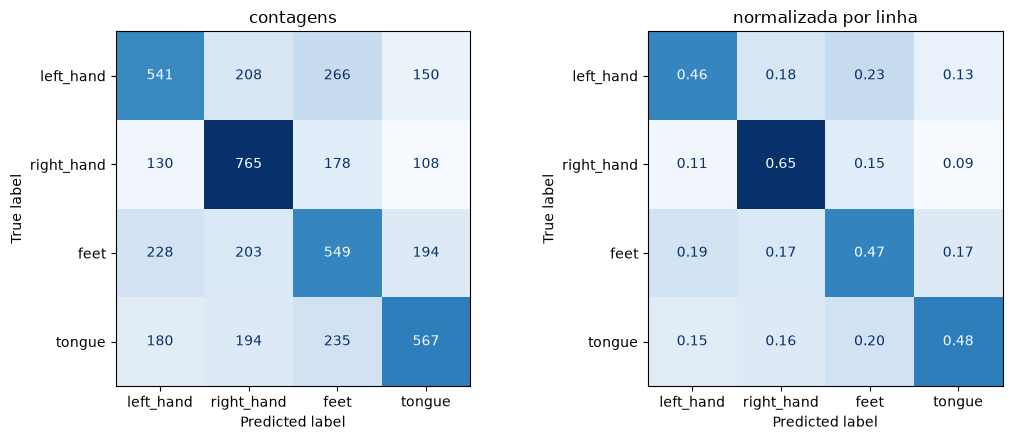

In [7]:
cm = confusion_matrix(clean["y_true"], clean["y_pred"])
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
ConfusionMatrixDisplay(cm, display_labels=CLASSES).plot(ax=axes[0], colorbar=False, cmap="Blues")
ConfusionMatrixDisplay(cm / cm.sum(1, keepdims=True), display_labels=CLASSES).plot(
    ax=axes[1], colorbar=False, cmap="Blues", values_format=".2f")
axes[0].set_title("contagens"); axes[1].set_title("normalizada por linha")
plt.tight_layout()

In [8]:
off = [(CLASSES[i], CLASSES[j], cm[i, j]) for i in range(4) for j in range(4) if i != j]
pd.DataFrame(off, columns=["verdadeira", "predita", "trials"]).sort_values("trials", ascending=False).head(6)

,verdadeira,predita,trials
1,left_hand,feet,266
11,tongue,feet,235
6,feet,left_hand,228
0,left_hand,right_hand,208
7,feet,right_hand,203
8,feet,tongue,194


## Erros por sujeito

Acurácia por sujeito (sem artefato) com IC 95% de Wilson. A variação entre sujeitos é a maior
fonte de erro em BCI cross-subject.

In [9]:
per_subject = clean.groupby("subject_id").agg(
    fold=("fold", "first"), n=("correct", "size"), acertos=("correct", "sum"))
ci = per_subject.apply(lambda r: wilson(r["acertos"], r["n"]), axis=1, result_type="expand")
per_subject[["acurácia", "IC 2,5%", "IC 97,5%"]] = ci
per_subject["kappa"] = clean.groupby("subject_id").apply(
    lambda g: cohen_kappa_score(g["y_true"], g["y_pred"]))
per_subject = per_subject.join(subjects.set_index("subject_id")[["age", "sex"]])
per_subject.round(3)

,fold,n,acertos,acurácia,"IC 2,5%","IC 97,5%",kappa,age,sex
subject_id,,,,,,,,,
A01,2,554,391,0.706,0.667,0.742,0.608,22,F
A02,1,553,222,0.401,0.361,0.443,0.202,24,F
A03,0,543,339,0.624,0.583,0.664,0.499,26,M
A04,2,490,220,0.449,0.406,0.493,0.262,24,F
A05,1,538,195,0.362,0.323,0.404,0.153,24,M
A06,0,434,169,0.389,0.345,0.436,0.182,23,F
A07,2,548,253,0.462,0.420,0.504,0.282,25,M
A08,1,535,383,0.716,0.676,0.752,0.621,23,M
A09,0,501,250,0.499,0.455,0.543,0.331,17,M


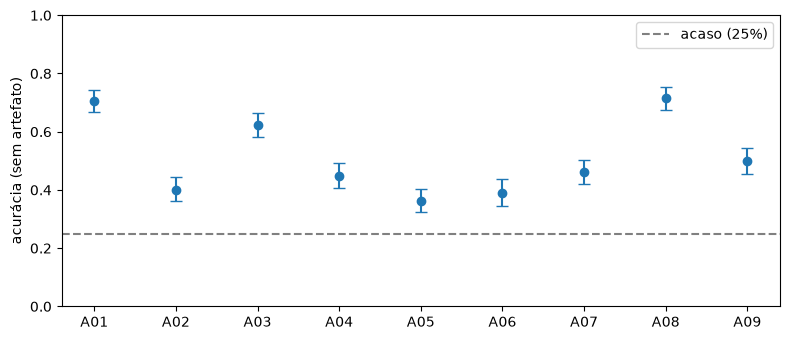

In [10]:
fig, ax = plt.subplots(figsize=(8, 3.5))
err = [per_subject["acurácia"] - per_subject["IC 2,5%"], per_subject["IC 97,5%"] - per_subject["acurácia"]]
ax.errorbar(per_subject.index, per_subject["acurácia"], yerr=err, fmt="o", capsize=4)
ax.axhline(0.25, ls="--", c="gray", label="acaso (25%)")
ax.set_ylabel("acurácia (sem artefato)"); ax.set_ylim(0, 1); ax.legend()
plt.tight_layout()

## Sessão, artefato e confiança

- **Sessão**: o modelo não viu nenhuma sessão do sujeito de teste, então `0train` e `1test` devem
  ter desempenho parecido (a diferença seria deriva entre dias).
- **Artefato**: trials marcados pela fonte nunca entraram no treino; aqui comparamos o acerto neles.
- Diferenças testadas com qui-quadrado (Fisher se alguma célula esperada < 5).

In [11]:
def compare(df, column):
    table = pd.crosstab(df[column], df["correct"])
    expected = stats.contingency.expected_freq(table.to_numpy())
    if (expected < 5).any():
        p, test_name = stats.fisher_exact(table.to_numpy())[1], "Fisher"
    else:
        p, test_name = stats.chi2_contingency(table.to_numpy())[1], "qui-quadrado"
    acc = df.groupby(column)["correct"].agg(["size", "mean"]).rename(columns={"size": "n", "mean": "acurácia"})
    print(f"{column}: {test_name}, p = {p:.3g}")
    return acc.round(3)


display(compare(clean, "session_id"))
display(compare(pred, "has_artifact"))

session_id: qui-quadrado, p = 0.779


,n,acurácia
session_id,,
0train,2328,0.518
1test,2368,0.514


has_artifact: qui-quadrado, p = 0.00561


,n,acurácia
has_artifact,,
False,4696,0.516
True,488,0.449


**Confiança** (maior probabilidade softmax) nos acertos e nos erros. Não é probabilidade
calibrada: 0,8 não quer dizer 80% de chance de acerto.

In [12]:
proba = clean[[f"p_{c}" for c in CLASSES]].to_numpy()
clean = clean.assign(confidence=proba.max(1))
print(clean.groupby("correct")["confidence"].describe().round(3))
u = stats.mannwhitneyu(clean.loc[clean["correct"], "confidence"], clean.loc[~clean["correct"], "confidence"])
print(f"Mann-Whitney p = {u.pvalue:.2e}")

bins = pd.cut(clean["confidence"], [0.25, 0.4, 0.5, 0.6, 0.7, 0.8, 1.0])
clean.groupby(bins, observed=True)["correct"].agg(n="size", acurácia="mean").round(3)

          count   mean    std    min    25%    50%    75%    max
correct                                                         
False    2274.0  0.583  0.160  0.261  0.464  0.554  0.695  0.986
True     2422.0  0.673  0.181  0.279  0.525  0.670  0.822  0.999
Mann-Whitney p = 0.00e+00


,n,acurácia
confidence,,
"(0.25, 0.4]",440,0.350
"(0.4, 0.5]",835,0.402
"(0.5, 0.6]",994,0.437
"(0.6, 0.7]",790,0.520
"(0.7, 0.8]",676,0.598
"(0.8, 1.0]",961,0.711


## Limitações

- **9 sujeitos.** O IC por bootstrap de sujeitos é largo (acurácia ~44–60%) e, com 9 grupos, é
  só aproximado. O acerto vai de 36% (A05) a 72% (A08), e a média esconde essa variação.
- **Época escolhida por um único sujeito de validação.** É uma escolha ruidosa. Os demais
  hiperparâmetros são os do artigo e do tutorial do braindecode, sem busca.
- **Cross-subject não é o protocolo da competição.** O padrão é within-subject (treino na sessão
  `T`, teste na `E` do mesmo sujeito), que costuma dar acurácia maior. Os números não se comparam
  diretamente com a tabela da competição.
- **"Pés" funciona como classe-ralo.** Mão esquerda e língua são preditas como pés com
  frequência, e pés tem a menor especificidade. Pés e língua não têm a lateralização mu/beta
  clara que separa as duas mãos.
- **Probabilidades não calibradas.** A confiança cresce com o acerto, mas os erros têm confiança
  média de 0,58.
- **Artefato.** Os trials marcados pela fonte erram mais. No uso real não há essa marcação, então
  o número "todos" é o mais próximo do uso.
- **Voluntários saudáveis em laboratório.** Nada aqui demonstra desempenho em pacientes (AVC, ELA).
- O teste binomial trata trials como independentes (otimista); p = 0 indica valor abaixo da
  precisão de float64.